# 06 · Generación masiva

**Objetivo:** preparar la generación de conjuntos grandes:

- prever cuánto ocupan (`gwsim.estimate_size`);
- repartir el trabajo entre procesos (`--workers`);
- recuperarse de una interrupción (`--resume`);
- leer un HDF5 grande por bloques sin llenar la memoria;
- organizar train/val/test en ficheros.

Aquí todo se hace con muy pocas señales, para que dure poco; los mismos comandos sirven para millones.

**Requisitos:** tutoriales 01 a 05. Paquete de PSD recomendable.

**Tiempo aproximado:** 2–3 minutos (unas 25 señales en total).

In [1]:
import sys, warnings, json, time, signal, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

O3B_GPS = [1256655618.0, 1269363618.0]
def noise_cfg(splits):
    if USE_PACK:
        return {'source': 'psd_pack', 'psd_pack': str(pack_path), 'splits': splits}
    return {'source': 'analytic', 'gps_range': O3B_GPS}

import gwsim
OUT = ROOT / 'tutorials' / 'salidas'
OUT.mkdir(exist_ok=True)

def fresh(path):
    # gwsim nunca sobrescribe: borramos la salida de una ejecución anterior de este notebook.
    path = Path(path)
    if path.exists():
        path.unlink()
    return path

def write_config(cfg, name):
    path = OUT / f'{name}.json'
    path.write_text(json.dumps(cfg, indent=1))
    return path

## 1. ¿Cuánto va a ocupar?

Cada salida pedida ocupa por señal 3 detectores × 16384 muestras × 4 bytes (float32) = **192 KiB**, más unos cientos de bytes de metadatos. `gwsim.estimate_size(config, n)` hace la cuenta sin comprimir. El fichero real suele ser algo menor, porque gwsim comprime con lzf, pero planifica el disco con la estimación.

In [2]:
combos = [['X'], ['X', 'X_noise'], ['X', 'X_noise', 'signal_whitened'],
          ['X', 'X_noise', 'X_unnormalized', 'signal_whitened', 'signal_projected', 'strain_noisy_raw']]
print(f'{"salidas":<75} {"10⁴":>9} {"10⁵":>9} {"10⁶":>9}')
for outs in combos:
    sizes = [gwsim.estimate_size({'outputs': outs}, n) / 2**30 for n in (10_000, 100_000, 1_000_000)]
    print(f'{", ".join(outs):<75} ' + ' '.join(f'{s:7.1f} G' for s in sizes))

salidas                                                                           10⁴       10⁵       10⁶


/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain

X                                                                               1.8 G    18.3 G   183.4 G
X, X_noise                                                                      3.7 G    36.7 G   366.5 G
X, X_noise, signal_whitened                                                     5.5 G    55.0 G   549.6 G
X, X_noise, X_unnormalized, signal_whitened, signal_projected, strain_noisy_raw    11.0 G   109.9 G  1099.0 G


Pide solo las salidas que vayas a usar: con las seis, cada señal ocupa seis veces más que con `X`. Si dudas, genera primero un conjunto pequeño con todas y decide.

## 2. Varios procesos: `--workers`

`--workers N` reparte las señales entre N procesos (creados con `fork`), en bloques que comparten bloque de ruido, para reutilizar sus PSD. Solo el proceso principal escribe en el HDF5, así que no hay conflictos.

- **Cuántos usar:** como mucho, los núcleos físicos menos uno.
- **Memoria:** cada proceso necesita la suya, del orden de cientos de MB; más con masas pequeñas, que dan señales más largas. La guía, en el paso 9, explica cómo medirla.
- El resultado **no depende** de N: todo el plan (parámetros, semillas, ruido) se sortea y se guarda antes de empezar.

In [3]:
cfg_demo = {'n_samples': 8, 'seed': 5, 'outputs': ['X', 'X_noise'], 'noise': noise_cfg(['train']),
            'prior': {'masses': {'distribution': 'components_uniform', 'range': [20.0, 60.0]}}}
demo_json = write_config(cfg_demo, 'demo_workers')
out_w = fresh(OUT / '05_workers.h5')
t0 = time.time()
!cd {ROOT} && python -m gwsim generate --config {demo_json} --output {out_w} --workers 2
print(f'{time.time() - t0:.0f} s en total')

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Creado /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/05_workers.h5: 8 filas
8 filas pendientes de 8; 2 proceso(s)
1/8 (hechas 1, fallidas 0); 5 s
2/8 (hechas 2, fallidas 0); 6 s
3/8 (hechas 3, fallidas 0); 7 s
4/8 (hechas 4, fallidas 0); 8 s
6/8 (hechas 6, fallidas 0); 8 s
7/8 (hechas 7, fallidas 0); 9 s
8/8 (hechas 8, fallidas 0); 9 s
Terminado: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/05_workers.h5 (hechas 8, fallidas 0)
22 s en total


## 3. Interrupción y `--resume`

Cada fila tiene un `status`: 0 pendiente, 1 hecha, 2 fallida. gwsim escribe primero los datos de la fila y **después** su status, así que una fila interrumpida a medias queda en 0. `--resume` rehace solo esas filas, y el resultado es idéntico al de una ejecución sin cortes.

Simulamos un corte: lanzamos la generación en segundo plano y, unos segundos después de que aparezca el fichero, le enviamos `SIGINT` (lo mismo que pulsar Ctrl-C).

In [4]:
cfg_cut = dict(cfg_demo, seed=6, outputs=['X'])
cut_json = write_config(cfg_cut, 'demo_resume')
out_r = fresh(OUT / '05_resume.h5')
cmd = [sys.executable, '-m', 'gwsim', 'generate', '--config', str(cut_json), '--output', str(out_r)]
proc = subprocess.Popen(cmd, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for _ in range(240):                       # esperamos a que exista el fichero (la importación de PyCBC tarda)
    if out_r.exists() or proc.poll() is not None:
        break
    time.sleep(0.5)
time.sleep(6)                              # dejamos que termine alguna fila
if proc.poll() is None:
    proc.send_signal(signal.SIGINT)        # como Ctrl-C
log, _ = proc.communicate(timeout=120)
print('\n'.join(log.strip().splitlines()[-4:]))

import h5py
with h5py.File(out_r, 'r') as h:
    st = h['status'][:]
print(f'\nTras el corte: hechas {int((st == 1).sum())}, pendientes {int((st == 0).sum())}, fallidas {int((st == 2).sum())}')

    return wav_gen(**input_params)
  File "/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/waveform.py", line 180, in _lalsim_td_waveform
    hp1, hc1 = lalsimulation.SimInspiralChooseTDWaveform(
KeyboardInterrupt

Tras el corte: hechas 1, pendientes 7, fallidas 0


La última línea del registro suele ser `KeyboardInterrupt`: es el corte que hemos provocado. Si tu ordenador es rápido y la generación terminó antes del `SIGINT`, no quedará nada pendiente; no pasa nada. Continuamos con **la misma configuración** y `--resume`:

In [5]:
!cd {ROOT} && python -m gwsim generate --config {cut_json} --output {out_r} --resume

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
7 filas pendientes de 8; 1 proceso(s)
2/8 (hechas 2, fallidas 0); 2 s
3/8 (hechas 3, fallidas 0); 3 s
4/8 (hechas 4, fallidas 0); 3 s
5/8 (hechas 5, fallidas 0); 4 s
6/8 (hechas 6, fallidas 0); 4 s
7/8 (hechas 7, fallidas 0); 5 s
8/8 (hechas 8, fallidas 0); 6 s
Terminado: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/05_resume.h5 (hechas 8, fallidas 0)


Si cambias la configuración entre medias (otra semilla, otro prior, otro `--n-samples`…), `--resume` se niega a continuar: el fichero mezclaría dos configuraciones. Compruébalo:

In [6]:
other_json = write_config(dict(cfg_cut, seed=7), 'demo_resume_otra')
!cd {ROOT} && python -m gwsim generate --config {other_json} --output {out_r} --resume

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
--resume con otra configuración: la del fichero (attrs['config_json']) es distinta. Usa la misma --config y los mismos overrides de la CLI


## 4. Leer un HDF5 grande por bloques

`gwsim.load` carga todo en memoria: con 10⁵ señales y `X` serían 18 GiB. Para ficheros grandes, abre el HDF5 con h5py y lee **bloques de filas**: cada `h['X'][i:j]` lee solo esas filas del disco.

Lo eficiente es leer rangos contiguos, filtrar después por `status == 1` y elegir el tamaño de bloque según la memoria: 1024 filas de `X` son 192 MiB. En el ejemplo, el bloque es de 3 filas solo para que se vea el bucle.

filas 0–2: 3 hechas
filas 3–5: 3 hechas
filas 6–7: 2 hechas


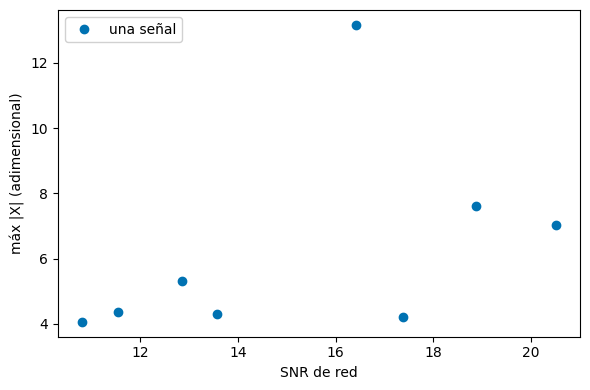

In [7]:
BLOCK = 3
peaks, snrs = [], []
with h5py.File(out_w, 'r') as h:
    n = h['status'].shape[0]
    for i in range(0, n, BLOCK):
        j = min(i + BLOCK, n)
        ok = h['status'][i:j] == 1
        X = h['X'][i:j][ok]                          # (≤ BLOCK, 3, 16384): solo este bloque en memoria
        peaks.extend(np.abs(X).max(axis=(1, 2)))
        snrs.extend(h['final_network_snr'][i:j][ok])
        print(f'filas {i}–{j - 1}: {int(ok.sum())} hechas')

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(snrs, peaks, 'o', color='#0072b2', label='una señal')
ax.set_xlabel('SNR de red')
ax.set_ylabel('máx |X| (adimensional)')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout(); plt.show()

Para entrenar redes, es habitual crear un `Dataset` que abra el fichero en cada proceso lector y lea por índices. Recuerda que h5py exige índices crecientes en la lectura con listas.

## 5. Organizar train/val/test

Una organización que funciona:

```
mi_estudio/
  configs/  train.json  val.json  test.json   <- una por conjunto: split de ruido y semilla distintos
  datos/    train.h5    val.h5    test.h5
  LEEME.txt                                    <- qué es cada fichero, comando usado y sha256 del paquete de PSD
```

Reglas:

1. **Un split del paquete por conjunto** (`noise.splits`), para que los entornos de ruido sean disjuntos.
2. **Una semilla distinta por conjunto**: con la misma semilla y el mismo prior saldrían las mismas fuentes.
3. **El mismo prior y el mismo procesado** en todos, salvo que el estudio pida lo contrario.
4. Cada HDF5 guarda su configuración completa en `attrs['config_json']`, así que un fichero siempre se puede reproducir.

Lo hacemos con 3 señales por conjunto:

In [8]:
base = {'n_samples': 3, 'outputs': ['X'],
        'prior': {'masses': {'distribution': 'components_uniform', 'range': [20.0, 60.0]}}}
for split, seed in (('train', 101), ('val', 202), ('test', 303)):
    cfg_path = write_config(dict(base, seed=seed, noise=noise_cfg([split])), f'mi_{split}')
    out_s = fresh(OUT / f'05_{split}.h5')
    !cd {ROOT} && python -m gwsim generate --config {cfg_path} --output {out_s}

blocks = {s: set(gwsim.load(OUT / f'05_{s}.h5', outputs=())['block_id']) for s in ('train', 'val', 'test')}
print('bloques comunes train ∩ test:', blocks['train'] & blocks['test'])
print('bloques comunes train ∩ val :', blocks['train'] & blocks['val'])
with h5py.File(OUT / '05_test.h5', 'r') as h:
    cfg_saved = json.loads(h.attrs['config_json'])
print('Configuración guardada en 05_test.h5 -> seed', cfg_saved['seed'], '| splits', cfg_saved['noise']['splits'])

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Creado /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/05_train.h5: 3 filas
3 filas pendientes de 3; 1 proceso(s)
1/3 (hechas 1, fallidas 0); 2 s
2/3 (hechas 2, fallidas 0); 3 s
3/3 (hechas 3, fallidas 0); 3 s
Terminado: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/05_train.h5 (hechas 3, fallidas 0)
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early a

Con el paquete de PSD, las intersecciones son vacías (`set()`). Con ruido analítico, todos los ficheros dicen `analytic` y la separación por entornos no existe.

Para un conjunto de verdad, la orden es la misma, con `n_samples` grande y `--workers`. Si es largo, lánzalo dentro de `tmux`, `screen` o `nohup … &`, para que sobreviva al cierre de la sesión, y continúa con `--resume` si se corta.

Fin de los tutoriales. Antes de sacar conclusiones, vuelve a leer `docs/VALIDEZ.md`.